# 28a. Reproducción de la evaluación ampliada

Este cuaderno regenera las tablas y figuras del capítulo 28 (robustez, conjuntos adicionales, ablación, calibración,
predicción conforme y costo computacional) desde la tabla maestra congelada (`tabla_maestra.csv`, la misma que lee el
dashboard) y desde las corridas versionadas. Todas las barras llevan su intervalo de confianza al 95 %.

In [1]:
# Configuración común. El cuaderno funciona desde docs/ (Jupyter Book) o desde la raíz del repositorio.
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable3").is_dir())
RES = REPO / "entregable3" / "resultados"   # tablas congeladas del análisis (hash SHA-256 en el capítulo 21)
RUNS = REPO / "entregable3" / "results"     # corridas versionadas, sin pesos
CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
COLOR = {"NAGFuse": "#c0392b", "ViT-B16": "#2e86c1", "RWCNet": "#27ae60", "GFN": "#8e44ad", "Celik-HC": "#d68910"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 4)
print("Repositorio:", REPO.name)

Repositorio: deep-learning-colaborativo


In [2]:
# Tabla maestra: una fila por modelo, media e IC 95 % (t) entre semillas para cada escenario
M = pd.read_csv(RES / "tabla_maestra.csv").set_index("modelo")
ESC = ["F1 limpio", "F1 ruido 0.05", "F1 ruido 0.10", "F1 desenfoque", "F1 oclusión", "F1 fondo",
       "F1 RealWaste", "F1 Garbage v2", "F1 WaRP-C"]
M[["R"] + ESC + ["ECE"]].sort_values("F1 limpio", ascending=False)

,R,F1 limpio,F1 ruido 0.05,F1 ruido 0.10,F1 desenfoque,F1 oclusión,F1 fondo,F1 RealWaste,F1 Garbage v2,F1 WaRP-C,ECE
modelo,,,,,,,,,,,
RWCNet,20,0.9369,0.5960,0.3430,0.8141,0.9260,0.8954,0.4255,0.5123,0.3316,0.0296
NAGFuse,20,0.9365,0.9036,0.8594,0.8645,0.9275,0.9198,0.4670,0.5227,0.3643,0.0297
ViT-B16,20,0.9363,0.8915,0.8395,0.8643,0.9317,0.9158,0.5198,0.5862,0.4357,0.0385
NAGFuse/sin_denoising,12,0.9313,0.8930,0.8553,0.8608,0.9237,0.9148,0.4757,0.5210,0.3479,0.0303
NAGFuse/solo_cnn,12,0.9272,0.6416,0.3837,0.8150,0.9064,0.8879,0.2791,0.5038,0.3253,0.0349
GFN,20,0.9240,0.7833,0.5221,0.7748,0.9223,0.8961,0.4154,0.5253,0.2880,0.0509
NAGFuse/solo_vit,12,0.9155,0.8921,0.8467,0.8289,0.9087,0.8873,0.4788,0.5121,0.3240,0.0531
Celik-HC,20,0.9092,0.2435,0.1282,0.7284,0.8924,0.8693,0.3568,0.4319,0.2825,0.0570
ResMsCapsule,20,0.9056,0.4269,0.1490,0.5781,0.8646,0.8126,0.3511,0.4150,0.2851,0.1884


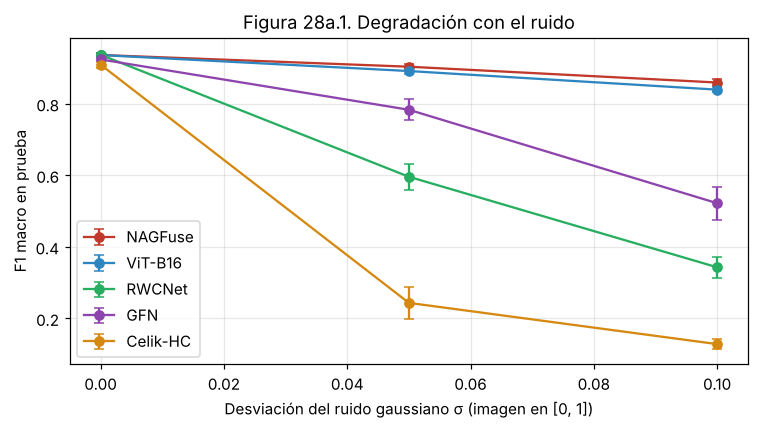

In [3]:
# Figura 28a.1: F1 macro frente a la intensidad del ruido gaussiano (media e IC 95 %)
fig, ax = plt.subplots(figsize=(7, 4))
cols, x = ["F1 limpio", "F1 ruido 0.05", "F1 ruido 0.10"], [0, 0.05, 0.10]
for m in ["NAGFuse", "ViT-B16", "RWCNet", "GFN", "Celik-HC"]:
    y = M.loc[m, cols].astype(float).values
    lo, hi = M.loc[m, [c + " IC_lo" for c in cols]].values, M.loc[m, [c + " IC_hi" for c in cols]].values
    ax.errorbar(x, y, yerr=[y - lo, hi - y], marker="o", capsize=3, color=COLOR[m], label=m)
ax.set_xlabel("Desviación del ruido gaussiano σ (imagen en [0, 1])"); ax.set_ylabel("F1 macro en prueba")
ax.set_title("Figura 28a.1. Degradación con el ruido"); ax.legend()
plt.tight_layout()

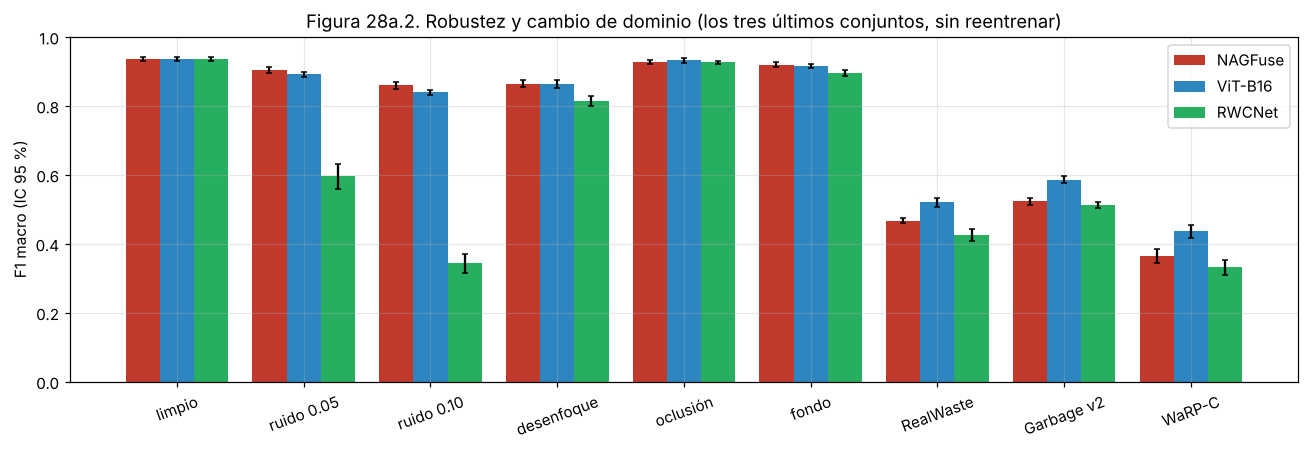

In [4]:
# Figura 28a.2: F1 macro por escenario (barras con IC 95 %) para NAGFuse y sus dos rivales más fuertes
mods = ["NAGFuse", "ViT-B16", "RWCNet"]; w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, m in enumerate(mods):
    y = M.loc[m, ESC].astype(float).values
    err = [y - M.loc[m, [c + " IC_lo" for c in ESC]].values, M.loc[m, [c + " IC_hi" for c in ESC]].values - y]
    ax.bar(np.arange(len(ESC)) + (i - 1) * w, y, w, yerr=err, capsize=2, color=COLOR[m], label=m)
ax.set_xticks(np.arange(len(ESC)), [c.replace("F1 ", "") for c in ESC], rotation=20)
ax.set_ylabel("F1 macro (IC 95 %)"); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Figura 28a.2. Robustez y cambio de dominio (los tres últimos conjuntos, sin reentrenar)")
plt.tight_layout()

**Interpretación.** NAGFuse conserva el F1 limpio del mejor rival y es el más estable ante ruido y desenfoque. En los
tres conjuntos adicionales (otro dominio, sin reentrenar) todos los modelos pierden entre 0.4 y 0.6 de F1 y
ViT-B16 queda por encima de NAGFuse: la mejora de robustez al ruido no se traduce en robustez al cambio de dominio.

In [5]:
# Tabla 28a.1: ablación (familia de Holm propia; 12 semillas). dif = completo − variante
A = pd.read_csv(RES / "ablacion.csv")
A[["cond", "variante", "completo", "variante_f1", "dif", "ic", "p_max_holm", "cliff"]]

,cond,variante,completo,variante_f1,dif,ic,p_max_holm,cliff
0,limpio,compuerta apagada,0.9339,0.9339,0.0000,"(np.float64(0.0), np.float64(0.0))",1.0000,0.0000
1,limpio,sin_denoising,0.9339,0.9313,0.0027,"(np.float64(-0.0058), np.float64(0.0104))",1.0000,0.1667
2,limpio,solo_vit,0.9339,0.9155,0.0185,"(np.float64(0.0104), np.float64(0.0277))",0.0098,0.6667
3,limpio,solo_cnn,0.9339,0.9272,0.0068,"(np.float64(0.0014), np.float64(0.0116))",0.1025,0.5000
4,ruido_0.05,compuerta apagada,0.9044,0.9032,0.0012,"(np.float64(-0.0033), np.float64(0.0057))",0.6772,0.1667
5,ruido_0.05,sin_denoising,0.9044,0.8930,0.0114,"(np.float64(-0.0004), np.float64(0.0235))",0.2979,0.5000
6,ruido_0.05,solo_vit,0.9044,0.8921,0.0123,"(np.float64(-0.0011), np.float64(0.0273))",0.4668,0.1667
7,ruido_0.05,solo_cnn,0.9044,0.6416,0.2628,"(np.float64(0.2381), np.float64(0.2882))",0.0020,1.0000
8,ruido_0.10,compuerta apagada,0.8604,0.8476,0.0127,"(np.float64(0.0065), np.float64(0.0188))",0.0146,0.8333
9,ruido_0.10,sin_denoising,0.8604,0.8553,0.0051,"(np.float64(-0.0152), np.float64(0.0277))",0.9097,0.1667


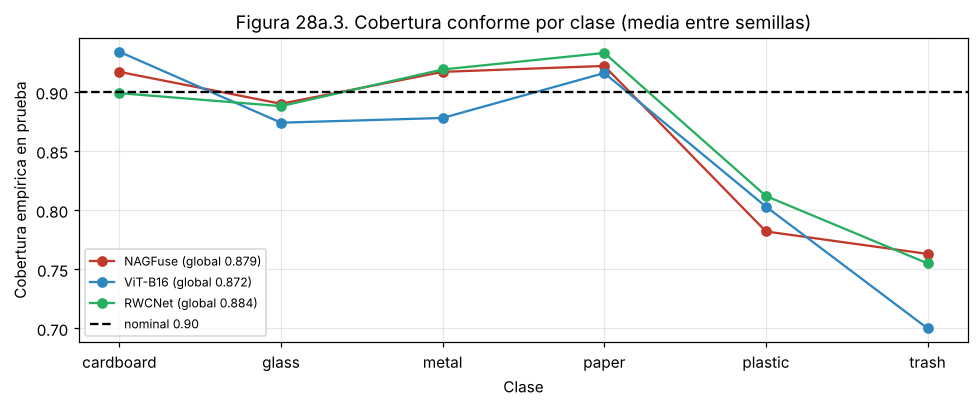

,R,cobertura,tamano,peor_clase
modelo,,,,
RWCNet,20,0.884,0.900,0.755
GFN,20,0.883,0.911,0.737
Celik-HC,20,0.882,0.915,0.663
NAGFuse,20,0.879,0.896,0.763
ViT-B16,20,0.872,0.890,0.700


In [6]:
# Tabla 28a.2 y figura 28a.3: cobertura empírica de la predicción conforme (LAC, nominal 90 %) por clase
C = pd.read_csv(RES / "conforme.csv").set_index("modelo")
cob = C[[f"cob_{c}" for c in CLASES]].rename(columns=lambda c: c[4:])
fig, ax = plt.subplots(figsize=(9, 3.8))
for m in ["NAGFuse", "ViT-B16", "RWCNet"]:
    ax.plot(CLASES, cob.loc[m], "o-", color=COLOR[m], label=f"{m} (global {C.loc[m, 'cobertura']:.3f})")
ax.axhline(0.90, color="black", ls="--", label="nominal 0.90")
ax.set_ylabel("Cobertura empírica en prueba"); ax.set_xlabel("Clase"); ax.legend(fontsize=8)
ax.set_title("Figura 28a.3. Cobertura conforme por clase (media entre semillas)")
plt.tight_layout()
C[["R", "cobertura", "tamano", "peor_clase"]].sort_values("cobertura", ascending=False)

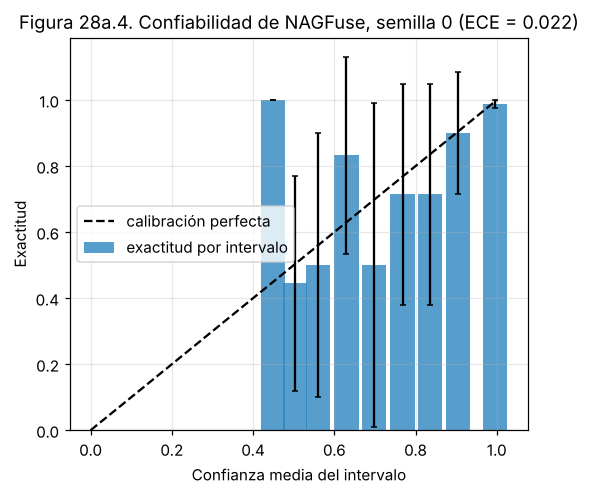

In [7]:
# Figura 28a.4: diagrama de confiabilidad de NAGFuse (semilla 0) recalculado desde las predicciones guardadas
tp = pickle.load(open(RUNS / "results_e2" / "NAGFuse" / "seed_00" / "test_predictions.pkl", "rb"))
P, y = tp["probs"], tp["y_true"]                       # P: (361, 6) probabilidades; y: (361,) clases reales
conf, acierto = P.max(1), (P.argmax(1) == y).astype(float)
b = np.minimum((conf * 15).astype(int), 14)            # 15 intervalos de confianza de igual ancho
n = np.bincount(b, minlength=15)
acc = np.bincount(b, acierto, 15) / np.maximum(n, 1); cmed = np.bincount(b, conf, 15) / np.maximum(n, 1)
ece = np.sum(n / len(y) * np.abs(acc - cmed))          # ECE = Σ (n_b / N) |exactitud_b − confianza_b|
v = n > 0
fig, ax = plt.subplots(figsize=(5, 4.6))
ee = np.sqrt(acc[v] * (1 - acc[v]) / n[v]) * 1.96      # IC 95 % binomial (aprox. normal) de la exactitud por intervalo
ax.bar(cmed[v], acc[v], width=0.06, yerr=ee, capsize=2, color="#2e86c1", alpha=0.8, label="exactitud por intervalo")
ax.plot([0, 1], [0, 1], "k--", label="calibración perfecta")
ax.set_xlabel("Confianza media del intervalo"); ax.set_ylabel("Exactitud"); ax.legend()
ax.set_title(f"Figura 28a.4. Confiabilidad de NAGFuse, semilla 0 (ECE = {ece:.3f})")
plt.tight_layout()

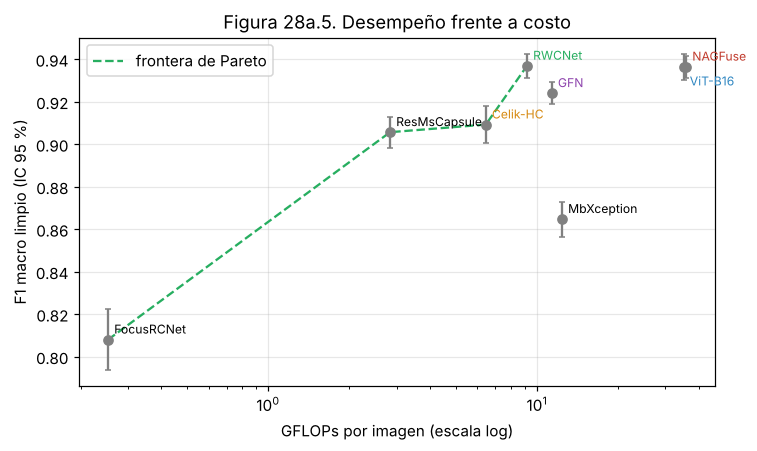

,parametros_M,GFLOPs,latencia_lote1_ms,entrenamiento_min,F1 limpio,Pareto
modelo,,,,,,
FocusRCNet,0.521,0.253,9.164,5.417,0.808,True
ResMsCapsule,4.217,2.840,4.950,5.236,0.906,True
Celik-HC,28.424,6.446,33.762,6.038,0.909,True
RWCNet,25.604,9.178,55.272,7.652,0.937,True
GFN,113.671,11.350,28.839,5.467,0.924,False
MbXception,28.393,12.390,10.125,5.846,0.865,False
ViT-B16,85.803,35.126,11.488,2.748,0.936,False
NAGFuse,89.819,35.895,29.123,5.081,0.936,False


In [8]:
# Tabla 28a.3 y figura 28a.5: costo computacional y frontera de Pareto (mediana entre semillas)
filas = []
for carpeta in (RUNS / "results_e2").iterdir():
    for s in carpeta.glob("seed_*"):
        if (s / "model_info.pkl").exists() and (s / "timing.pkl").exists():
            mi, t = pickle.load(open(s / "model_info.pkl", "rb")), pickle.load(open(s / "timing.pkl", "rb"))
            filas.append({"modelo": mi["model"], "parametros_M": mi["params_total"] / 1e6, "GFLOPs": mi.get("gflops"),
                          "latencia_lote1_ms": t["inference"]["latency_bs1_ms_mean"],
                          "entrenamiento_min": t["train_time_s"] / 60})
K = pd.DataFrame(filas).groupby("modelo").median()
K["F1 limpio"] = M["F1 limpio"]
K = K.dropna().sort_values("GFLOPs")
K["Pareto"] = K["F1 limpio"] >= K["F1 limpio"].cummax()        # nadie más barato tiene mejor F1
fig, ax = plt.subplots(figsize=(7, 4.2))
lo, hi = M.loc[K.index, "F1 limpio IC_lo"], M.loc[K.index, "F1 limpio IC_hi"]
ax.errorbar(K.GFLOPs, K["F1 limpio"], yerr=[K["F1 limpio"] - lo, hi - K["F1 limpio"]], fmt="o", color="gray", capsize=2)
ax.plot(K.GFLOPs[K.Pareto], K["F1 limpio"][K.Pareto], "--", color="#27ae60", label="frontera de Pareto")
for m, r in K.iterrows():
    ax.annotate(m, (r.GFLOPs, r["F1 limpio"]), fontsize=8, xytext=(4, -12 if m == "ViT-B16" else 4), textcoords="offset points",
                color=COLOR.get(m, "black"))
ax.set_xscale("log"); ax.set_xlabel("GFLOPs por imagen (escala log)"); ax.set_ylabel("F1 macro limpio (IC 95 %)")
ax.set_title("Figura 28a.5. Desempeño frente a costo"); ax.legend()
plt.tight_layout()
K.round(3)

**Control de capacidad.** NAGFuse (89.8 M de parámetros, 35.9 GFLOPs) tiene un tamaño comparable al de ViT-B16
(85.8 M, 35.1 GFLOPs), que forma parte de la familia de contrastes con 20 semillas. La comparación con ViT-B16 hace
de variante del benchmark de tamaño comparable: con casi el mismo cómputo, NAGFuse empata en limpio y no lo supera
con ruido. Además, la ablación (tabla 28a.1) compara contra cada rama sola con el mismo protocolo.

In [9]:
# Tabla 28a.4: calibración antes y después del escalado de temperatura (ajustado en validación), media entre semillas
filas = []
for carpeta in (RUNS / "results_e2").iterdir():
    for s in carpeta.glob("seed_*"):
        if (s / "calibration.pkl").exists():
            c = pickle.load(open(s / "calibration.pkl", "rb"))
            if c.get("aplicable"):
                filas.append({"modelo": carpeta.name, "T": c["temperature"],
                              **{f"{k} antes": c["antes"][k] for k in ["ece", "nll", "brier"]},
                              **{f"{k} después": c["despues"][k] for k in ["ece", "nll", "brier"]}})
CAL = pd.DataFrame(filas).groupby("modelo").agg(["mean", "std"])
CAL.columns = [f"{a} ({'media' if b == 'mean' else 'DE'})" for a, b in CAL.columns]
CAL[[c for c in CAL.columns if "media" in c]].sort_values("ece antes (media)").round(4)

,T (media),ece antes (media),nll antes (media),brier antes (media),ece después (media),nll después (media),brier después (media)
modelo,,,,,,,
NAGFuse,1.0752,0.0297,0.1911,0.0142,0.0282,0.1879,0.0141
RWCNet,1.2749,0.0312,0.1944,0.0146,0.0238,0.1785,0.0142
ViT-B16,1.2346,0.0365,0.2143,0.0149,0.0291,0.1917,0.0145
MbXception,1.5113,0.0507,0.3904,0.0287,0.0403,0.3591,0.0287
GFN,1.5564,0.0509,0.3055,0.0179,0.0319,0.2294,0.0167
FocusRCNet,2.2989,0.1088,0.7959,0.0479,0.0535,0.5309,0.0436
ResMsCapsule,0.5289,0.1851,0.4207,0.0282,0.0346,0.2940,0.0203


**Interpretación.** El escalado de temperatura (un solo parámetro $T$ ajustado en validación) reduce el ECE de todos
los modelos sin cambiar sus predicciones, porque no altera el orden de las probabilidades. Un $T$ cercano a 1 indica
que el modelo ya estaba bien calibrado. Los diagramas de confiabilidad por intervalo están en la figura 28a.4 y en el
dashboard.

In [10]:
# Tabla 28a.5 (exploratoria): sensibilidad del F1 macro a los hiperparámetros propios de la compuerta, ρ y s_lo.
# Usa las salidas guardadas de la semilla 0 (p_V, p_C y σ̂ por imagen): π se recalcula y la mezcla se rehace sin
# reentrenar, porque ninguna rama depende de ρ ni de s_lo. Es un análisis posterior, no confirmatorio.
IMG = pd.read_csv(REPO / "dashboard" / "data" / "nagfuse_s00_por_imagen.csv.gz")
PI0, SLO = 0.509, 0.014535                       # valores congelados en el protocolo (π0 de validación, cuantil 0.99)

def f1_macro(y, yp):
    return np.mean([2 * np.sum((yp == k) & (y == k)) / max(np.sum(yp == k) + np.sum(y == k), 1) for k in range(6)])

filas = []
for rho in [1.5, 2.0, 3.0, 4.0]:
    for fac in [0.5, 1.0, 2.0]:
        r = {"ρ": rho, "s_lo": f"{fac} × {SLO}"}
        for cond in ["limpio", "ruido_0.05", "ruido_0.10"]:
            d = IMG[IMG.cond == cond]; s_lo = fac * SLO
            g = np.clip((d.sigma.values - s_lo) / ((rho - 1) * s_lo), 0, 1)       # compuerta g(σ̂)
            pi = PI0 + (1 - PI0) * g                                               # peso de la rama ViT
            pv, pc = d[[f"pv_{k}" for k in range(6)]].values, d[[f"pc_{k}" for k in range(6)]].values
            r[f"F1 {cond}"] = f1_macro(d.y.values, (pi[:, None] * pv + (1 - pi[:, None]) * pc).argmax(1))
        filas.append(r)
SENS = pd.DataFrame(filas)
SENS.round(4)

,ρ,s_lo,F1 limpio,F1 ruido_0.05,F1 ruido_0.10
0,1.5,0.5 × 0.014535,0.9416,0.9141,0.8574
1,1.5,1.0 × 0.014535,0.9392,0.9141,0.8574
2,1.5,2.0 × 0.014535,0.9392,0.9141,0.8574
3,2.0,0.5 × 0.014535,0.9416,0.9141,0.8574
4,2.0,1.0 × 0.014535,0.9392,0.9141,0.8574
5,2.0,2.0 × 0.014535,0.9392,0.9141,0.8574
6,3.0,0.5 × 0.014535,0.9392,0.9141,0.8574
7,3.0,1.0 × 0.014535,0.9392,0.9141,0.8574
8,3.0,2.0 × 0.014535,0.9392,0.9166,0.8574
9,4.0,0.5 × 0.014535,0.9392,0.9141,0.8574


**Interpretación.** El valor preregistrado ($\rho = 2$, $s_{lo}$ = cuantil 0.99) está marcado por la fila
$\rho = 2.0$, $1.0 \times s_{lo}$. En toda la rejilla ($\rho$ de 1.5 a 4 y $s_{lo}$ de la mitad al doble) el F1 cambia como
máximo 0.0025, muy por debajo de $\delta$: el resultado no depende de esta elección. La razón es que $\hat\sigma$
separa con claridad las dos situaciones: en limpio es casi siempre 0 (la compuerta queda cerrada) y con ruido supera
con holgura cualquier umbral razonable (la compuerta se abre del todo).

In [11]:
# Tabla 28a.6: análisis de errores de NAGFuse (semilla 0). Pares de clases más confundidos por condición
# y comparación imagen a imagen con su rama ViT (p_V), que es el modelo más fuerte con ruido.
filas = []
for cond in ["limpio", "ruido_0.05", "ruido_0.10"]:
    d = IMG[IMG.cond == cond]; y = d.y.values; yn = d.pred.values
    yv = d[[f"pv_{k}" for k in range(6)]].values.argmax(1)
    pares = pd.Series([f"{CLASES[a]} → {CLASES[b]}" for a, b in zip(y[yn != y], yn[yn != y])]).value_counts()
    filas.append({"condición": cond, "errores NAGFuse": int((yn != y).sum()), "errores rama ViT": int((yv != y).sum()),
                  "NAGFuse falla y ViT acierta": int(((yn != y) & (yv == y)).sum()),
                  "ViT falla y NAGFuse acierta": int(((yv != y) & (yn == y)).sum()),
                  "3 confusiones más frecuentes": "; ".join(f"{k} ({v})" for k, v in pares.head(3).items())})
pd.DataFrame(filas)

,condición,errores NAGFuse,errores rama ViT,NAGFuse falla y ViT acierta,ViT falla y NAGFuse acierta,3 confusiones más frecuentes
0,limpio,20,24,1,5,plastic → glass (4); cardboard → paper (3); glass → metal (3)
1,ruido_0.05,27,27,0,0,plastic → glass (4); cardboard → paper (3); glass → metal (3)
2,ruido_0.10,43,43,0,0,cardboard → paper (6); glass → plastic (5); glass → metal (4)


**Interpretación.** Los errores se concentran en pares de materiales visualmente parecidos (por ejemplo, papel y
cartón, o vidrio y plástico) y en la clase trash, la menos frecuente y la más heterogénea. Con ruido, NAGFuse y su rama ViT
cometen exactamente los mismos errores, porque $\pi = 1$ y la mezcla es la rama ViT. En limpio, la mezcla corrige 5
errores de la rama ViT y comete 1 nuevo (semilla 0): ahí es donde la rama convolucional aporta.

**Interpretación del costo.** NAGFuse es el modelo más costoso (≈ 36 GFLOPs, dos redes en paralelo) y **no está en
la frontera de Pareto del F1 limpio**: RWCNet logra el mismo F1 con la cuarta parte del cómputo. El costo adicional
solo se justifica por la robustez al ruido (figura 28a.1), donde RWCNet colapsa. La latencia se midió en GPU A100 con AMP;
la latencia en CPU del modelo exportado se mide en el dashboard.

**Consumo energético estimado.** Las 144 tareas de entrenamiento sumaron 19.1 h de GPU A100. Con una potencia media
de 0.25–0.40 kW (rango del consumo nominal de la tarjeta), el consumo estimado es de 5–8 kWh. Es una estimación por
potencia nominal, no una medición.